In [2]:
%pip install tensorboard

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.5 MB ? eta -:--:--
   --- ------------------------------------ 0.5/5.5 MB 662.4 kB/s eta 0:00:08
   --- ------------------------------------ 0.5/5.5 MB 662.4 kB/s eta 0:00:08
   ----- ---------------------------------- 0.8/5.5 MB 642.8 kB/s eta 0:00:08
   ------- -------------------------------- 1.0/5.5 MB 789.4 kB/s eta 0:00:06
   ----------- ---------------------------- 1.6/5.5 MB 978.8 kB/s eta 0:00:05
   ------------- -------------------------- 1.8/5.5 MB 1.0 MB/s eta 0:00:04
   --------------- ------------------------ 2.1/5.5 MB 1.1 MB/s eta 0:00:04
   ------------------- ------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\dgaid\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training Experiment 1
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9258 - loss: 0.2485 - val_accuracy: 0.9446 - val_loss: 0.1889
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9534 - loss: 0.1639 - val_accuracy: 0.9499 - val_loss: 0.1908
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9612 - loss: 0.1412 - val_accuracy: 0.9577 - val_loss: 0.1653
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9644 - loss: 0.1333 - val_accuracy: 0.9574 - val_loss: 0.1848
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9676 - loss: 0.1250 - val_accuracy: 0.9574 - val_loss: 0.2040

Training Experiment 2
Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9139 - loss: 0.2983 - val_accuracy: 0.9581 - val_loss: 0.1464
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9644 - loss: 0.1182 - val_accuracy: 0.9649 - val_loss: 0.1113
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - a

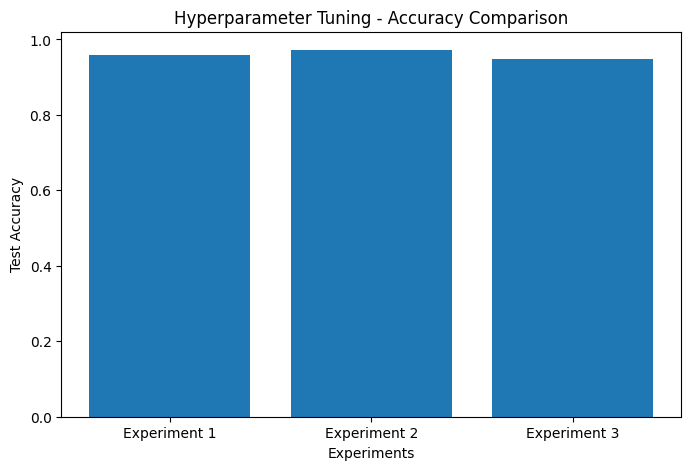

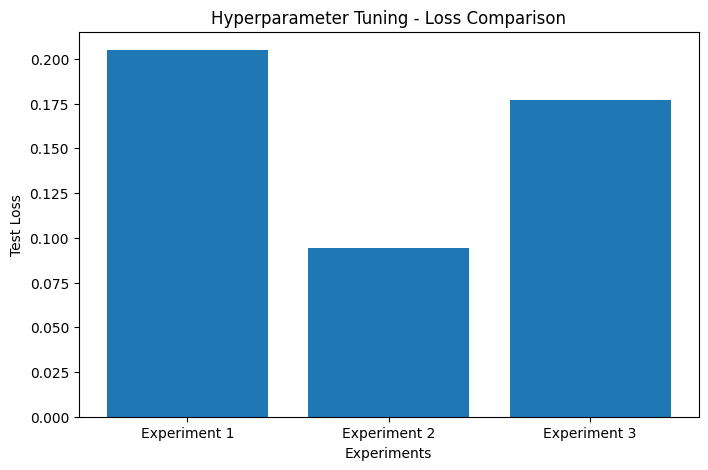

In [1]:
# Step 1: Import Libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.callbacks import TensorBoard
from tensorflow.keras.datasets import mnist

# Step 2: Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Step 3: Normalize Data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Step 4: Define Hyperparameter Configurations
configs = [
    {"lr": 0.01, "batch": 32, "layers": 1},
    {"lr": 0.001, "batch": 64, "layers": 2},
    {"lr": 0.0001, "batch": 128, "layers": 3}
]

results = []

# Step 5: Train Models with Different Hyperparameters
for i, config in enumerate(configs):

    model = Sequential()
    model.add(Flatten(input_shape=(28, 28)))

    for j in range(config["layers"]):
        model.add(Dense(128, activation='relu'))

    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=config["lr"]
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # TensorBoard Logging
    log_dir = f"logs/experiment_{i+1}"

    tensorboard = TensorBoard(log_dir=log_dir)

    print(f"\nTraining Experiment {i+1}")

    history = model.fit(
        x_train, y_train,
        epochs=5,
        batch_size=config["batch"],
        validation_split=0.2,
        callbacks=[tensorboard],
        verbose=1
    )

    # Evaluate Model
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results.append([
        config["lr"],
        config["batch"],
        config["layers"],
        accuracy,
        loss
    ])

# Step 6: Display Comparison
df = pd.DataFrame(results, columns=[
    "Learning Rate",
    "Batch Size",
    "Hidden Layers",
    "Test Accuracy",
    "Test Loss"
])

print("\nHyperparameter Comparison:")
print(df)

# Step 7: Plot Accuracy Comparison
plt.figure(figsize=(8, 5))

plt.bar(
    ["Experiment 1", "Experiment 2", "Experiment 3"],
    df["Test Accuracy"]
)

plt.xlabel("Experiments")
plt.ylabel("Test Accuracy")
plt.title("Hyperparameter Tuning - Accuracy Comparison")
plt.show()

# Step 8: Plot Loss Comparison
plt.figure(figsize=(8, 5))

plt.bar(
    ["Experiment 1", "Experiment 2", "Experiment 3"],
    df["Test Loss"]
)

plt.xlabel("Experiments")
plt.ylabel("Test Loss")
plt.title("Hyperparameter Tuning - Loss Comparison")
plt.show()

In [3]:
%load_ext tensorboard

In [4]:
%tensorboard --logdir=logs

C:\Users\dgaid\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training Experiment 1
Epoch 1/3
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 13ms/step - accuracy: 0.9265 - loss: 0.2503 - val_accuracy: 0.9502 - val_loss: 0.1620
Epoch 2/3
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9529 - loss: 0.1609 - val_accuracy: 0.9553 - val_loss: 0.1643
Epoch 3/3
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9602 - loss: 0.1467 - val_accuracy: 0.9507 - val_loss: 0.2055

Training Experiment 2
Epoch 1/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9162 - loss: 0.2936 - val_accuracy: 0.9580 - val_loss: 0.1445
Epoch 2/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9636 - loss: 0.1213 - val_accuracy: 0.9636 - val_loss: 0.1190
Epoch 3/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9744 - loss: 0.0831 - val_accuracy: 0.9692 - val_loss: 0.0981

Training Experiment 3
Epoch 1/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.7384 - loss: 1.0043 - val_accuracy: 0.9007 - val_loss: 0.3629
Epoch 2/3
375/375 ━━━━━

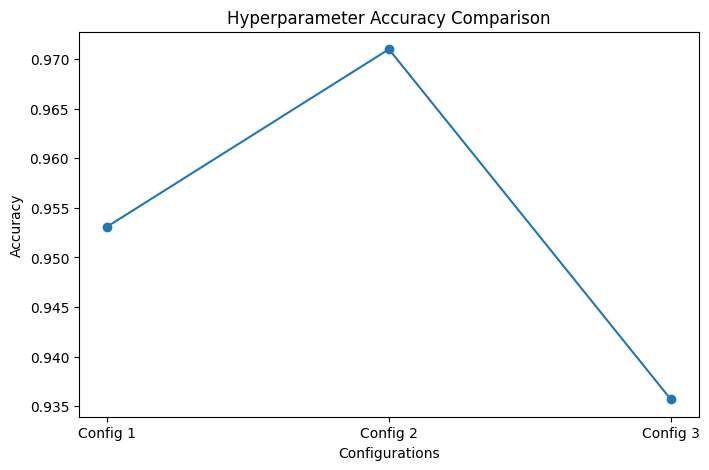

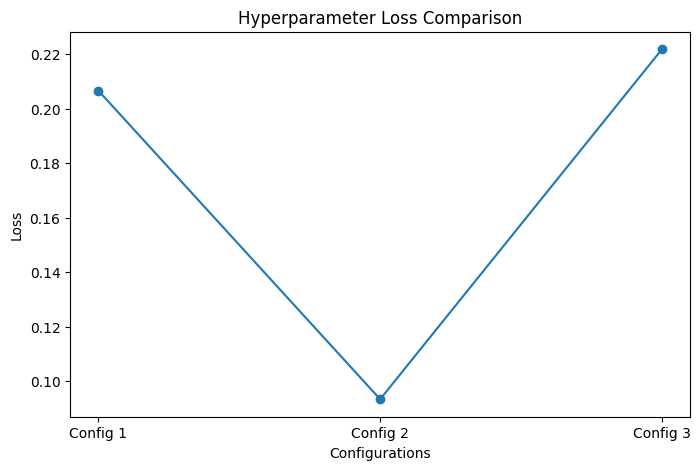

In [5]:
# Step 1: Import Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras.callbacks import TensorBoard

# Step 2: Load Local MNIST Dataset
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

# Step 3: Normalize Data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Step 4: Define Hyperparameter Configurations
configs = [
    [0.01, 32, 1],
    [0.001, 64, 2],
    [0.0001, 128, 3]
]

results = []

# Step 5: Train Models with Different Configurations
for i, (lr, batch, layers) in enumerate(configs):

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

    for j in range(layers):
        model.add(tf.keras.layers.Dense(128, activation='relu'))

    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # TensorBoard Logging
    tb = TensorBoard(log_dir=f'logs/experiment_{i+1}')

    print(f"\nTraining Experiment {i+1}")

    model.fit(
        x_train, y_train,
        epochs=3,
        batch_size=batch,
        validation_split=0.2,
        callbacks=[tb],
        verbose=1
    )

    # Evaluate Model
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results.append([lr, batch, layers, accuracy, loss])

# Step 6: Display Comparison Table
df = pd.DataFrame(results, columns=[
    'Learning Rate', 'Batch Size', 'Layers',
    'Accuracy', 'Loss'
])

print("\nHyperparameter Comparison:")
print(df)

# Step 7: Plot Accuracy Comparison
plt.figure(figsize=(8, 5))
plt.plot(df['Accuracy'], marker='o')
plt.xticks([0, 1, 2], ['Config 1', 'Config 2', 'Config 3'])
plt.xlabel('Configurations')
plt.ylabel('Accuracy')
plt.title('Hyperparameter Accuracy Comparison')
plt.show()

# Step 8: Plot Loss Comparison
plt.figure(figsize=(8, 5))
plt.plot(df['Loss'], marker='o')
plt.xticks([0, 1, 2], ['Config 1', 'Config 2', 'Config 3'])
plt.xlabel('Configurations')
plt.ylabel('Loss')
plt.title('Hyperparameter Loss Comparison')
plt.show()

In [6]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard
